In [13]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [14]:
df = pd.read_csv("Downloads/ACME-HappinessSurvey2020.csv") 
print(df.head())
print(df.shape)

   Y  X1  X2  X3  X4  X5  X6
0  0   3   3   3   4   2   4
1  0   3   2   3   5   4   3
2  1   5   3   3   3   3   5
3  0   5   4   3   3   3   5
4  0   5   4   3   3   3   5
(126, 7)


Classifiers

In [15]:
# df: columns X1..X6 (1-5), Y (0/1)
features = ['X1','X2','X3','X4','X5','X6']
X = df[features]
y = df['Y']

In [16]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [18]:

model = RandomForestClassifier(
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [20]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [21]:
# Baseline: logistic regression
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

lr_scores = cross_val_score(lr, X, y, cv=cv)

print("LR:", lr_scores.mean())

LR: 0.5550769230769231


In [22]:
# Accuracy leader: gradient boosting
gb = GradientBoostingClassifier(random_state=42)

gb_scores = cross_val_score(gb, X, y, cv=cv)

print("GBM:", gb_scores.mean())

GBM: 0.6107692307692308


In [23]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

rf_scores = cross_val_score(
    rf,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Random Forest CV Scores:", rf_scores)
print("Mean Accuracy:", np.mean(rf_scores))

Random Forest CV Scores: [0.65384615 0.64       0.6        0.6        0.4       ]
Mean Accuracy: 0.5787692307692308


In [24]:
#extra trees classifier
from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(
    n_estimators=500,
    random_state=42
)

et_scores = cross_val_score(
    et,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Extra Trees CV Scores:", et_scores)
print("Mean Accuracy:", np.mean(et_scores))

Extra Trees CV Scores: [0.65384615 0.64       0.6        0.56       0.56      ]
Mean Accuracy: 0.6027692307692308


In [25]:
X_no_x4 = X.drop(columns=['X4'])

In [26]:
model.fit(X_no_x4, y)

RandomForestClassifier(random_state=42)

In [28]:
# Baseline
X_baseline = X.copy()

# Without X4
X_no_x4 = X.drop(columns=['X4'])

from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)

baseline_score = cross_val_score(
    model,
    X_baseline,
    y,
    cv=5,
    scoring='accuracy'
).mean()

x4_removed_score = cross_val_score(
    model,
    X_no_x4,
    y,
    cv=5,
    scoring='accuracy'
).mean()

print("Baseline:", baseline_score)
print("Without X4:", x4_removed_score)

Baseline: 0.5553846153846154
Without X4: 0.5713846153846154


Features to remove for best accuracy

In [29]:
model.fit(X, y)

import pandas as pd

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

print(importance)

  Feature  Importance
2      X3    0.197599
1      X2    0.177116
4      X5    0.175312
0      X1    0.172084
3      X4    0.147127
5      X6    0.130761


In [33]:
features = ['X1','X2','X3','X4','X5','X6']

for feature in features:
    X_temp = X.drop(columns=[feature])

    score = cross_val_score(
        lr,
        X_temp,
        y,
        cv=cv,
        scoring='accuracy'
    ).mean()

    print(f"Without {feature}: {score:.4f}")

Without X1: 0.5240
Without X2: 0.5551
Without X3: 0.5554
Without X4: 0.5471
Without X5: 0.5711
Without X6: 0.5791


In [34]:
from itertools import combinations

features = ['X1','X2','X3','X4','X5','X6']

for combo in combinations(features, 2):

    X_temp = X.drop(columns=list(combo))

    score = cross_val_score(
        lr,
        X_temp,
        y,
        cv=cv,
        scoring='accuracy'
    ).mean()

    print(f"Removed {combo}: {score:.4f}")

Removed ('X1', 'X2'): 0.5397
Removed ('X1', 'X3'): 0.5317
Removed ('X1', 'X4'): 0.5160
Removed ('X1', 'X5'): 0.5714
Removed ('X1', 'X6'): 0.5640
Removed ('X2', 'X3'): 0.5794
Removed ('X2', 'X4'): 0.5711
Removed ('X2', 'X5'): 0.5871
Removed ('X2', 'X6'): 0.5711
Removed ('X3', 'X4'): 0.5551
Removed ('X3', 'X5'): 0.5945
Removed ('X3', 'X6'): 0.5871
Removed ('X4', 'X5'): 0.5714
Removed ('X4', 'X6'): 0.5791
Removed ('X5', 'X6'): 0.5711


In [35]:
for combo in combinations(features, 3):

    X_temp = X.drop(columns=list(combo))

    score = cross_val_score(
        lr,
        X_temp,
        y,
        cv=cv,
        scoring='accuracy'
    ).mean()

    print(f"Removed {combo}: {score:.4f}")

Removed ('X1', 'X2', 'X3'): 0.5557
Removed ('X1', 'X2', 'X4'): 0.5317
Removed ('X1', 'X2', 'X5'): 0.5554
Removed ('X1', 'X2', 'X6'): 0.5957
Removed ('X1', 'X3', 'X4'): 0.5314
Removed ('X1', 'X3', 'X5'): 0.5551
Removed ('X1', 'X3', 'X6'): 0.5874
Removed ('X1', 'X4', 'X5'): 0.6114
Removed ('X1', 'X4', 'X6'): 0.5480
Removed ('X1', 'X5', 'X6'): 0.5637
Removed ('X2', 'X3', 'X4'): 0.5871
Removed ('X2', 'X3', 'X5'): 0.5945
Removed ('X2', 'X3', 'X6'): 0.5791
Removed ('X2', 'X4', 'X5'): 0.5714
Removed ('X2', 'X4', 'X6'): 0.5711
Removed ('X2', 'X5', 'X6'): 0.5951
Removed ('X3', 'X4', 'X5'): 0.6025
Removed ('X3', 'X4', 'X6'): 0.5871
Removed ('X3', 'X5', 'X6'): 0.6025
Removed ('X4', 'X5', 'X6'): 0.5711


In [36]:
from itertools import combinations

features = ['X1','X2','X3','X4','X5','X6']

best_score = 0
best_combo = None

for r in range(1, 4):  # test removing 1, 2, or 3 features

    for combo in combinations(features, r):

        X_temp = X.drop(columns=list(combo))

        score = cross_val_score(
            lr,
            X_temp,
            y,
            cv=cv,
            scoring='accuracy'
        ).mean()

        if score > best_score:
            best_score = score
            best_combo = combo

print("Best Features to Remove:", best_combo)
print("Best Accuracy:", best_score)

Best Features to Remove: ('X1', 'X4', 'X5')
Best Accuracy: 0.6113846153846154


In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from itertools import combinations

rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

features = ['X1','X2','X3','X4','X5','X6']

best_score = 0
best_combo = None

for r in range(1, 4):  # test removing 1, 2, or 3 features

    for combo in combinations(features, r):

        X_temp = X.drop(columns=list(combo))

        score = cross_val_score(
            rf,
            X_temp,
            y,
            cv=cv,
            scoring='accuracy'
        ).mean()

        print(f"Removed {combo}: {score:.4f}")

        if score > best_score:
            best_score = score
            best_combo = combo

print("\nBest Features to Remove:", best_combo)
print("Best Accuracy:", best_score)

Removed ('X1',): 0.5545
Removed ('X2',): 0.6108
Removed ('X3',): 0.6188
Removed ('X4',): 0.6031
Removed ('X5',): 0.6508
Removed ('X6',): 0.6185
Removed ('X1', 'X2'): 0.5480
Removed ('X1', 'X3'): 0.5631
Removed ('X1', 'X4'): 0.5074
Removed ('X1', 'X5'): 0.5317
Removed ('X1', 'X6'): 0.5868
Removed ('X2', 'X3'): 0.6194
Removed ('X2', 'X4'): 0.6505
Removed ('X2', 'X5'): 0.6742
Removed ('X2', 'X6'): 0.6031
Removed ('X3', 'X4'): 0.5877
Removed ('X3', 'X5'): 0.6117
Removed ('X3', 'X6'): 0.5948
Removed ('X4', 'X5'): 0.6274
Removed ('X4', 'X6'): 0.6265
Removed ('X5', 'X6'): 0.6105
Removed ('X1', 'X2', 'X3'): 0.5240
Removed ('X1', 'X2', 'X4'): 0.5080
Removed ('X1', 'X2', 'X5'): 0.5391
Removed ('X1', 'X2', 'X6'): 0.5800
Removed ('X1', 'X3', 'X4'): 0.5871
Removed ('X1', 'X3', 'X5'): 0.4766
Removed ('X1', 'X3', 'X6'): 0.6351
Removed ('X1', 'X4', 'X5'): 0.4843
Removed ('X1', 'X4', 'X6'): 0.5717
Removed ('X1', 'X5', 'X6'): 0.5391
Removed ('X2', 'X3', 'X4'): 0.6508
Removed ('X2', 'X3', 'X5'): 0.6197
R

In [38]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from itertools import combinations

gb = GradientBoostingClassifier(
    random_state=42
)

features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6']

best_score = 0
best_combo = None

for r in range(1, 4):  # remove 1, 2, or 3 features

    for combo in combinations(features, r):

        X_temp = X.drop(columns=list(combo))

        score = cross_val_score(
            gb,
            X_temp,
            y,
            cv=cv,
            scoring='accuracy'
        ).mean()

        print(f"Removed {combo}: {score:.4f}")

        if score > best_score:
            best_score = score
            best_combo = combo

print("\nBest Features to Remove:", best_combo)
print("Best Accuracy:", best_score)

Removed ('X1',): 0.5474
Removed ('X2',): 0.6582
Removed ('X3',): 0.6505
Removed ('X4',): 0.6265
Removed ('X5',): 0.6028
Removed ('X6',): 0.6108
Removed ('X1', 'X2'): 0.5240
Removed ('X1', 'X3'): 0.5865
Removed ('X1', 'X4'): 0.5554
Removed ('X1', 'X5'): 0.5560
Removed ('X1', 'X6'): 0.5942
Removed ('X2', 'X3'): 0.6105
Removed ('X2', 'X4'): 0.6582
Removed ('X2', 'X5'): 0.6578
Removed ('X2', 'X6'): 0.5951
Removed ('X3', 'X4'): 0.6342
Removed ('X3', 'X5'): 0.5883
Removed ('X3', 'X6'): 0.6345
Removed ('X4', 'X5'): 0.6351
Removed ('X4', 'X6'): 0.6425
Removed ('X5', 'X6'): 0.6102
Removed ('X1', 'X2', 'X3'): 0.5394
Removed ('X1', 'X2', 'X4'): 0.5080
Removed ('X1', 'X2', 'X5'): 0.5631
Removed ('X1', 'X2', 'X6'): 0.5640
Removed ('X1', 'X3', 'X4'): 0.5791
Removed ('X1', 'X3', 'X5'): 0.4689
Removed ('X1', 'X3', 'X6'): 0.6182
Removed ('X1', 'X4', 'X5'): 0.4763
Removed ('X1', 'X4', 'X6'): 0.5154
Removed ('X1', 'X5', 'X6'): 0.5311
Removed ('X2', 'X3', 'X4'): 0.6505
Removed ('X2', 'X3', 'X5'): 0.5723
R

In [40]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

gb = GradientBoostingClassifier(
    random_state=42
)

X_no_x2_x5 = X.drop(columns=['X2', 'X5'])

scores = cross_val_score(
    gb,
    X_no_x2_x5,
    y,
    cv=cv,
    scoring='accuracy'
)

print("CV Scores:", scores)
print("Mean Accuracy:", scores.mean())

CV Scores: [0.76923077 0.72       0.6        0.56       0.64      ]
Mean Accuracy: 0.657846153846154


In [45]:
from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(
    n_estimators=500,
    random_state=42
)

scores = cross_val_score(
    et,
    X_reduced,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Extra Trees:", scores.mean())

Extra Trees: 0.713846153846154


In [61]:
et = ExtraTreesClassifier(
    n_estimators=5000,
    random_state=42
)

scores = cross_val_score(
    et,
    X_reduced,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Extra Trees:", scores.mean())

Extra Trees: 0.713846153846154


In [63]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import cross_val_score

best_score = 0
best_seed = None

for seed in range(0, 101):

    et = ExtraTreesClassifier(
        n_estimators=500,
        random_state=seed
    )

    score = cross_val_score(
        et,
        X_reduced,
        y,
        cv=cv,
        scoring='accuracy'
    ).mean()

    if score > best_score:
        best_score = score
        best_seed = seed

    print(f"Seed {seed}: {score:.4f}")

print("\nBest Seed:", best_seed)
print("Best Accuracy:", best_score)

Seed 0: 0.7138
Seed 1: 0.7218
Seed 2: 0.7058
Seed 3: 0.7138
Seed 4: 0.7138
Seed 5: 0.7138
Seed 6: 0.7138
Seed 7: 0.7058
Seed 8: 0.7138
Seed 9: 0.7218
Seed 10: 0.7218
Seed 11: 0.7218
Seed 12: 0.7138
Seed 13: 0.7138
Seed 14: 0.7218
Seed 15: 0.7138
Seed 16: 0.7218
Seed 17: 0.7058
Seed 18: 0.7295
Seed 19: 0.7138
Seed 20: 0.7138
Seed 21: 0.7218
Seed 22: 0.7138
Seed 23: 0.6978
Seed 24: 0.7138
Seed 25: 0.7138
Seed 26: 0.7138
Seed 27: 0.7138
Seed 28: 0.7138
Seed 29: 0.7218
Seed 30: 0.7218
Seed 31: 0.7138
Seed 32: 0.7058
Seed 33: 0.7138
Seed 34: 0.7058
Seed 35: 0.7138
Seed 36: 0.7138
Seed 37: 0.7218
Seed 38: 0.7298
Seed 39: 0.7138
Seed 40: 0.7138
Seed 41: 0.7138
Seed 42: 0.7138
Seed 43: 0.7218
Seed 44: 0.7138
Seed 45: 0.7218
Seed 46: 0.7138
Seed 47: 0.7218
Seed 48: 0.7218
Seed 49: 0.7138
Seed 50: 0.7138
Seed 51: 0.7058
Seed 52: 0.7058
Seed 53: 0.7218
Seed 54: 0.7138
Seed 55: 0.7138
Seed 56: 0.7058
Seed 57: 0.7218
Seed 58: 0.7218
Seed 59: 0.7138
Seed 60: 0.7138
Seed 61: 0.7218
Seed 62: 0.7218
Se

In [47]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    random_state=42
)

scores = cross_val_score(
    dt,
    X_reduced,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Decision Tree:", scores.mean())

Decision Tree: 0.681846153846154


In [62]:
et.fit(X, y)

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': et.feature_importances_
})

print(
    importance.sort_values(
        'Importance',
        ascending=False
    )
)

  Feature  Importance
2      X3    0.189442
1      X2    0.186015
0      X1    0.181839
4      X5    0.157389
3      X4    0.153259
5      X6    0.132056


In [67]:
from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(
    n_estimators=500,
    random_state=42
)

et.fit(X, y)

ExtraTreesClassifier(n_estimators=500, random_state=42)

Visuals

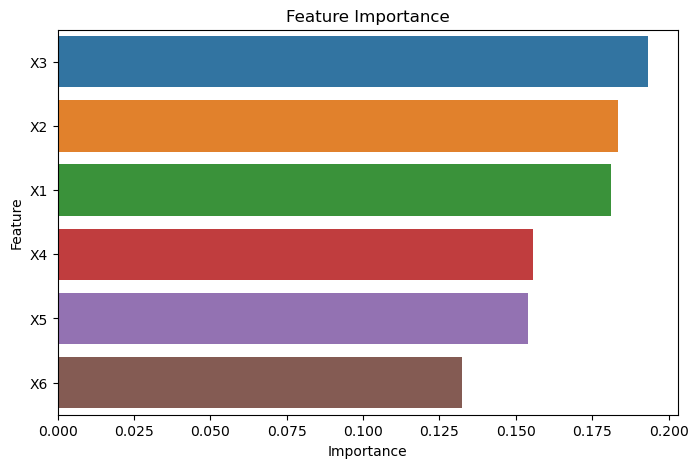

In [68]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': et.feature_importances_
})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance')
plt.show()

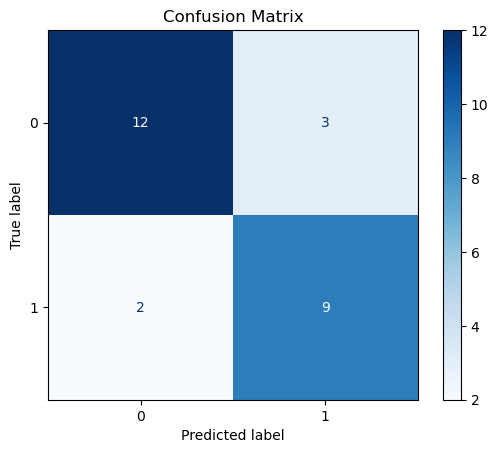

In [69]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(
    X_reduced,
    y,
    test_size=0.2,
    random_state=42
)

et.fit(X_train, y_train)

y_pred = et.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap='Blues'
)

plt.title('Confusion Matrix')
plt.show()

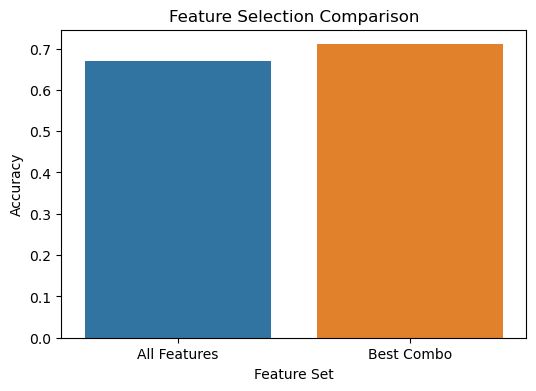

In [71]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

feature_results = pd.DataFrame({
    'Feature Set': [
        'All Features',
        'Best Combo'
    ],
    'Accuracy': [
        0.67,   
        0.71    
    ]
})

plt.figure(figsize=(6,4))

sns.barplot(
    data=feature_results,
    x='Feature Set',
    y='Accuracy'
)

plt.title('Feature Selection Comparison')
plt.ylabel('Accuracy')

plt.show()
    

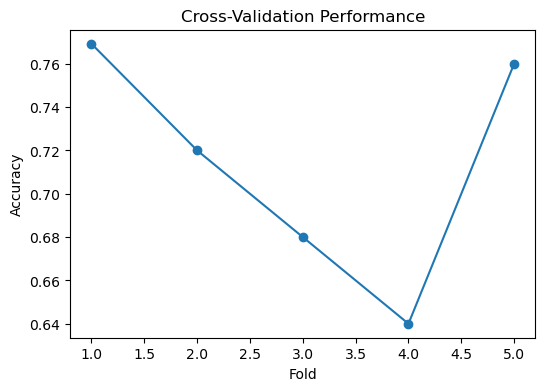

In [72]:
plt.figure(figsize=(6,4))

plt.plot(
    range(1, len(scores)+1),
    scores,
    marker='o'
)

plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.title('Cross-Validation Performance')

plt.show()

Important Features

In [73]:
rf.fit(X, y)

importance_df = (
    pd.DataFrame({
        'Feature': X.columns,
        'Importance': rf.feature_importances_
    })
    .sort_values('Importance', ascending=False)
)

print(importance_df)

  Feature  Importance
2      X3    0.186960
1      X2    0.180792
4      X5    0.180622
0      X1    0.163803
3      X4    0.155261
5      X6    0.132562


In [74]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

rfe = RFE(model, n_features_to_select=1)
rfe.fit(X, y)

feature_ranking = pd.DataFrame({
    'Feature': X.columns,
    'Rank': rfe.ranking_
}).sort_values('Rank')

print(feature_ranking)

  Feature  Rank
0      X1     1
4      X5     2
2      X3     3
5      X6     4
1      X2     5
3      X4     6


In [77]:
from itertools import combinations
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import cross_val_score
import pandas as pd

results = []

for k in range(1, len(X.columns) + 1):

    for subset in combinations(X.columns, k):

        score = cross_val_score(
            ExtraTreesClassifier(
                n_estimators=500,
                random_state=42
            ),
            X[list(subset)],
            y,
            cv=cv,
            scoring='accuracy'
        ).mean()

        results.append({
            'Features': subset,
            'Num_Features': k,
            'Accuracy': score
        })

results_df = pd.DataFrame(results)

results_df.sort_values(
    'Accuracy',
    ascending=False
).head(20)

,Features,Num_Features,Accuracy
48,"(X1, X3, X4, X6)",4,0.713846
23,"(X1, X2, X5)",3,0.674154
10,"(X1, X6)",2,0.667077
27,"(X1, X3, X6)",3,0.666462
9,"(X1, X5)",2,0.650462
0,"(X1,)",1,0.650154
49,"(X1, X3, X5, X6)",4,0.642462
26,"(X1, X3, X5)",3,0.642462
30,"(X1, X5, X6)",3,0.642154
28,"(X1, X4, X5)",3,0.634769


In [78]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

print(importance)

  Feature  Importance
2      X3    0.197599
1      X2    0.177116
4      X5    0.175312
0      X1    0.172084
3      X4    0.147127
5      X6    0.130761


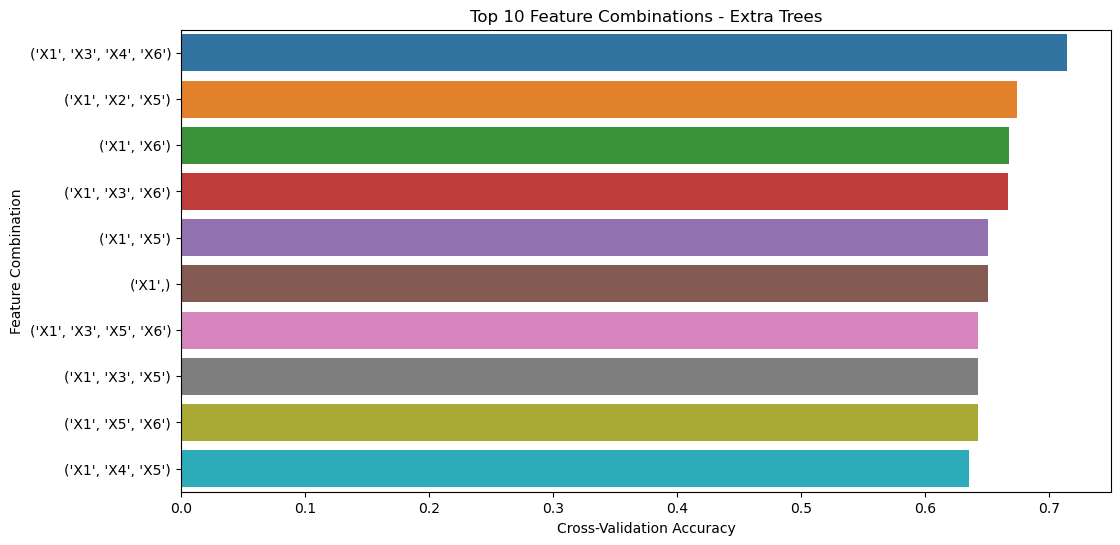

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

top10 = results_df.sort_values(
    'Accuracy',
    ascending=False
).head(10)

top10['Features'] = top10['Features'].astype(str)

plt.figure(figsize=(12,6))

sns.barplot(
    data=top10,
    x='Accuracy',
    y='Features'
)

plt.title('Top 10 Feature Combinations - Extra Trees')
plt.xlabel('Cross-Validation Accuracy')
plt.ylabel('Feature Combination')

plt.show()